# Build the AlphaGenome support table from original file mappings

The input is `file_mappings` CSV. The workflow is:

**file_mappings → ENCODE file/experiment metadata → ontology + assay → comparison
with AlphaGenome RNA-seq metadata → support-summary CSV**.

ENCODE is queried for each accession. Raw API responses are cached so reruns do not
repeat completed requests. AlphaGenome metadata is exported if its CSV is absent;
set `ALPHAGENOME_API_KEY` before that first export. Existing metadata is reused
explicitly and its source hash is recorded.


In [1]:
from pathlib import Path
import sys
import pandas as pd

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / 'benchmarks/expression/scripts/build_alphagenome_ontology_map.py').exists())
sys.path.insert(0, str(ROOT / 'benchmarks/expression/scripts'))
import build_alphagenome_ontology_map as support

# Change these two values for your own data.
FILE_MAPPINGS = ROOT / 'data/file_mappings_borzoi_and_v1_human.csv'
ORGANISM = 'human'  # or 'mouse'

suffix = '_mouse' if ORGANISM == 'mouse' else ''
DATA = ROOT / 'benchmarks/expression/data'
CACHE = ROOT / f'data/encode_metadata_cache{suffix}.json'
ONTOLOGY_MAP = DATA / f'qnorm_alphagenome_ontology_map{suffix}.csv'
AG_METADATA = DATA / f'alphagenome_{ORGANISM}_rna_seq_metadata.csv'
OUTPUT = DATA / f'qnorm_alphagenome_support_summary{suffix}.csv'
print('Input:', FILE_MAPPINGS)
print('Output:', OUTPUT)


Input: /media/eternus1/nfs/projects/dpanchenko/BenchAG/data/file_mappings_borzoi_and_v1_human.csv
Output: /media/eternus1/nfs/projects/dpanchenko/BenchAG/benchmarks/expression/data/qnorm_alphagenome_support_summary.csv


## 1. Read the original file mappings

Required: `id`, containing the sample identifier used in your expression tables.
The resolver tries ENCODE accessions in `id`, `targets_identifier_base`, and
`original_id`, in that order. File mappings may retain all their other columns
(expression-file paths, descriptions, etc.); these are not needed for this lookup.
If `genome` or `assembly` is present, select human or mouse rows using that column.
The selected input must have unique sample IDs.


In [2]:
input_rows = support.read_file_mappings(FILE_MAPPINGS, ORGANISM)
input_table = pd.DataFrame(input_rows)
preview_columns = [c for c in ['id', 'original_id', 'targets_identifier_base', 'genome', 'assembly'] if c in input_table]
print('Selected sample rows:', len(input_rows))
print(input_table[preview_columns].head(8).to_string(index=False))


Selected sample rows: 815
         id original_id genome
ENCFF731CJY ENCFF168OLY GRCh38
ENCFF242NRP ENCFF153YEN GRCh38
ENCFF465EDA ENCFF366CCB GRCh38
ENCFF152CYS ENCFF805UDX GRCh38
ENCFF900QOK ENCFF079OMS GRCh38
ENCFF708BZY ENCFF114NWW GRCh38
ENCFF225PNB ENCFF520FAO GRCh38
ENCFF898FAP ENCFF556PAF GRCh38


## 2. Find the ontology and assay in ENCODE

An `ENCFF…` accession is looked up at `/files/<accession>/?format=json`; an
`ENCSR…` accession at `/experiments/<accession>/?format=json`. We read the biosample
ontology (`term_id`, name, classification) and the RNA-seq assay title. When a file
stores these fields on its parent experiment, follow that relationship. If one
candidate accession fails, try the next one from the same input row.

Keep unresolved rows and their error messages: a failed lookup is different from
an ontology that is known not to be supported. The cache contains the **raw ENCODE
response objects**, not a precomputed ontology table.


In [3]:
resolved_rows = support.resolve_rows(input_rows, CACHE)
support.write_csv(ONTOLOGY_MAP, resolved_rows)
resolved = pd.DataFrame(resolved_rows)
print('Rows with ontology and assay:', ((resolved.ontology_curie != '') & (resolved.assay != '')).sum())
print(resolved[['id','query_accession','ontology_curie','biosample_name','assay','errors']].head(10).to_string(index=False))
print('Saved:', ONTOLOGY_MAP)


ENCODE: 25/815
ENCODE: 50/815
ENCODE: 75/815
ENCODE: 100/815
ENCODE: 125/815
ENCODE: 150/815
ENCODE: 175/815
ENCODE: 200/815
ENCODE: 225/815
ENCODE: 250/815
ENCODE: 275/815
ENCODE: 300/815
ENCODE: 325/815
ENCODE: 350/815
ENCODE: 375/815
ENCODE: 400/815
ENCODE: 425/815
ENCODE: 450/815
ENCODE: 475/815
ENCODE: 500/815
ENCODE: 525/815
ENCODE: 550/815
ENCODE: 575/815
ENCODE: 600/815
ENCODE: 625/815
ENCODE: 650/815
ENCODE: 675/815
ENCODE: 700/815
ENCODE: 725/815
ENCODE: 750/815
ENCODE: 775/815
ENCODE: 800/815
Rows with ontology and assay: 815
         id query_accession ontology_curie                                                               biosample_name         assay errors
ENCFF731CJY     ENCFF731CJY     CL:2000040                                       bladder microvascular endothelial cell total RNA-seq       
ENCFF242NRP     ENCFF242NRP     CL:0002328                                                    bronchial epithelial cell total RNA-seq       
ENCFF465EDA     ENCFF465EDA     CL

## 3. Get AlphaGenome RNA-seq metadata

Use the metadata for the same organism as the sample list. It contains output
`name`, `ontology_curie`, and `strand`. The canonical output name combines an
ontology and assay, e.g. `UBERON:0006631 total RNA-seq`. The general `Assay title`
field can be broader than the assay in that name; match the canonical name.

The following cell reuses an existing CSV, or exports it from the API when absent.
To deliberately refresh it, run `dump_alphagenome_rna_metadata.py --organism ...`
with a separate output path and point `AG_METADATA` to that file.


In [4]:
metadata_rows = support.get_ag_metadata(ORGANISM, AG_METADATA, reuse=AG_METADATA.exists())
metadata = pd.DataFrame(metadata_rows)
print('AlphaGenome strand-level rows:', len(metadata))
print('Unique ontology IDs:', metadata.ontology_curie.nunique())
print('Unique ontology-assay names:', metadata.name.nunique())
print(metadata[['name','ontology_curie','strand']].head(8).to_string(index=False))


AlphaGenome strand-level rows: 667
Unique ontology IDs: 285
Unique ontology-assay names: 371
                         name ontology_curie strand
CL:0000047 polyA plus RNA-seq     CL:0000047      +
     CL:0000062 total RNA-seq     CL:0000062      +
CL:0000084 polyA plus RNA-seq     CL:0000084      +
     CL:0000084 total RNA-seq     CL:0000084      +
     CL:0000115 total RNA-seq     CL:0000115      +
     CL:0000127 total RNA-seq     CL:0000127      +
CL:0000134 polyA plus RNA-seq     CL:0000134      +
     CL:0000137 total RNA-seq     CL:0000137      +


## 4. Build the comparison table

There is one output row for every selected file-mapping sample. The original
`id` remains unchanged so the table can be joined back to measured-expression data.

| Column | Meaning |
|---|---|
| `query_accession` | ENCODE accession that supplied the metadata |
| `ontology_curie`, `biosample_name`, `assay` | Resolved ENCODE tissue/cell ontology and assay |
| `alphagenome_supported` | Whether the ontology exists in AG at all (legacy ontology-only flag) |
| `alphagenome_rna_track_count` | Number of AG strand-level rows with that ontology |
| `alphagenome_ontology_assay_supported` | Whether the exact ontology AND assay name exists |
| `alphagenome_ontology_name` | Matched canonical AG output name |
| `alphagenome_ontology_assay_track_count` | Number of AG rows for that exact name |
| `alphagenome_strands` | Strands available for the matched name |
| `match_status`, `errors` | Why the match failed or which lookup errors occurred |

Use the **exact ontology–assay flag** when selecting prediction outputs. An ontology
can be present but measured with a different assay. None of these flags claims that
the experimental files themselves are identical or that every gene/strand will have
a returned prediction.


In [5]:
summary_rows = support.support_rows(resolved_rows, metadata_rows)
support.write_csv(OUTPUT, summary_rows)
summary = pd.DataFrame(summary_rows)
columns = ['id','ontology_curie','assay','alphagenome_supported',
           'alphagenome_ontology_assay_supported','alphagenome_ontology_name','alphagenome_strands','match_status']
print(summary[columns].head(12).to_string(index=False))
print('Match status counts:')
print(summary.match_status.value_counts().to_string())
print('Experimental samples with an exact match:', (summary.alphagenome_ontology_assay_supported == 'yes').sum())
print('Shared ontology-assay names:', summary.loc[summary.alphagenome_ontology_assay_supported == 'yes','alphagenome_ontology_name'].nunique())
print('Saved:', OUTPUT)


         id ontology_curie         assay alphagenome_supported alphagenome_ontology_assay_supported alphagenome_ontology_name alphagenome_strands match_status
ENCFF731CJY     CL:2000040 total RNA-seq                   yes                                  yes  CL:2000040 total RNA-seq                 +,-      matched
ENCFF242NRP     CL:0002328 total RNA-seq                   yes                                  yes  CL:0002328 total RNA-seq                 +,-      matched
ENCFF465EDA     CL:2000010 total RNA-seq                   yes                                  yes  CL:2000010 total RNA-seq                 +,-      matched
ENCFF152CYS     CL:2000011 total RNA-seq                   yes                                  yes  CL:2000011 total RNA-seq                 +,-      matched
ENCFF900QOK     CL:2000041 total RNA-seq                   yes                                  yes  CL:2000041 total RNA-seq                 +,-      matched
ENCFF708BZY     CL:2000094 total RNA-seq      

## Track coverage and ontology–assay overlap

This figure uses the complete selected input (815 human tracks, including the three expression-v1 tracks), as in the reference sketch.
The upper panel is a schematic of matching by ontology–assay name: 770 experimental tracks correspond to 552 AG strand-level outputs. These are different sets of tracks, not 552 identical experimental files.
The lower panel compares sets of exact ontology–assay names. Ontology IDs alone are counted separately in the annotations. Circle areas are illustrative, not proportional.


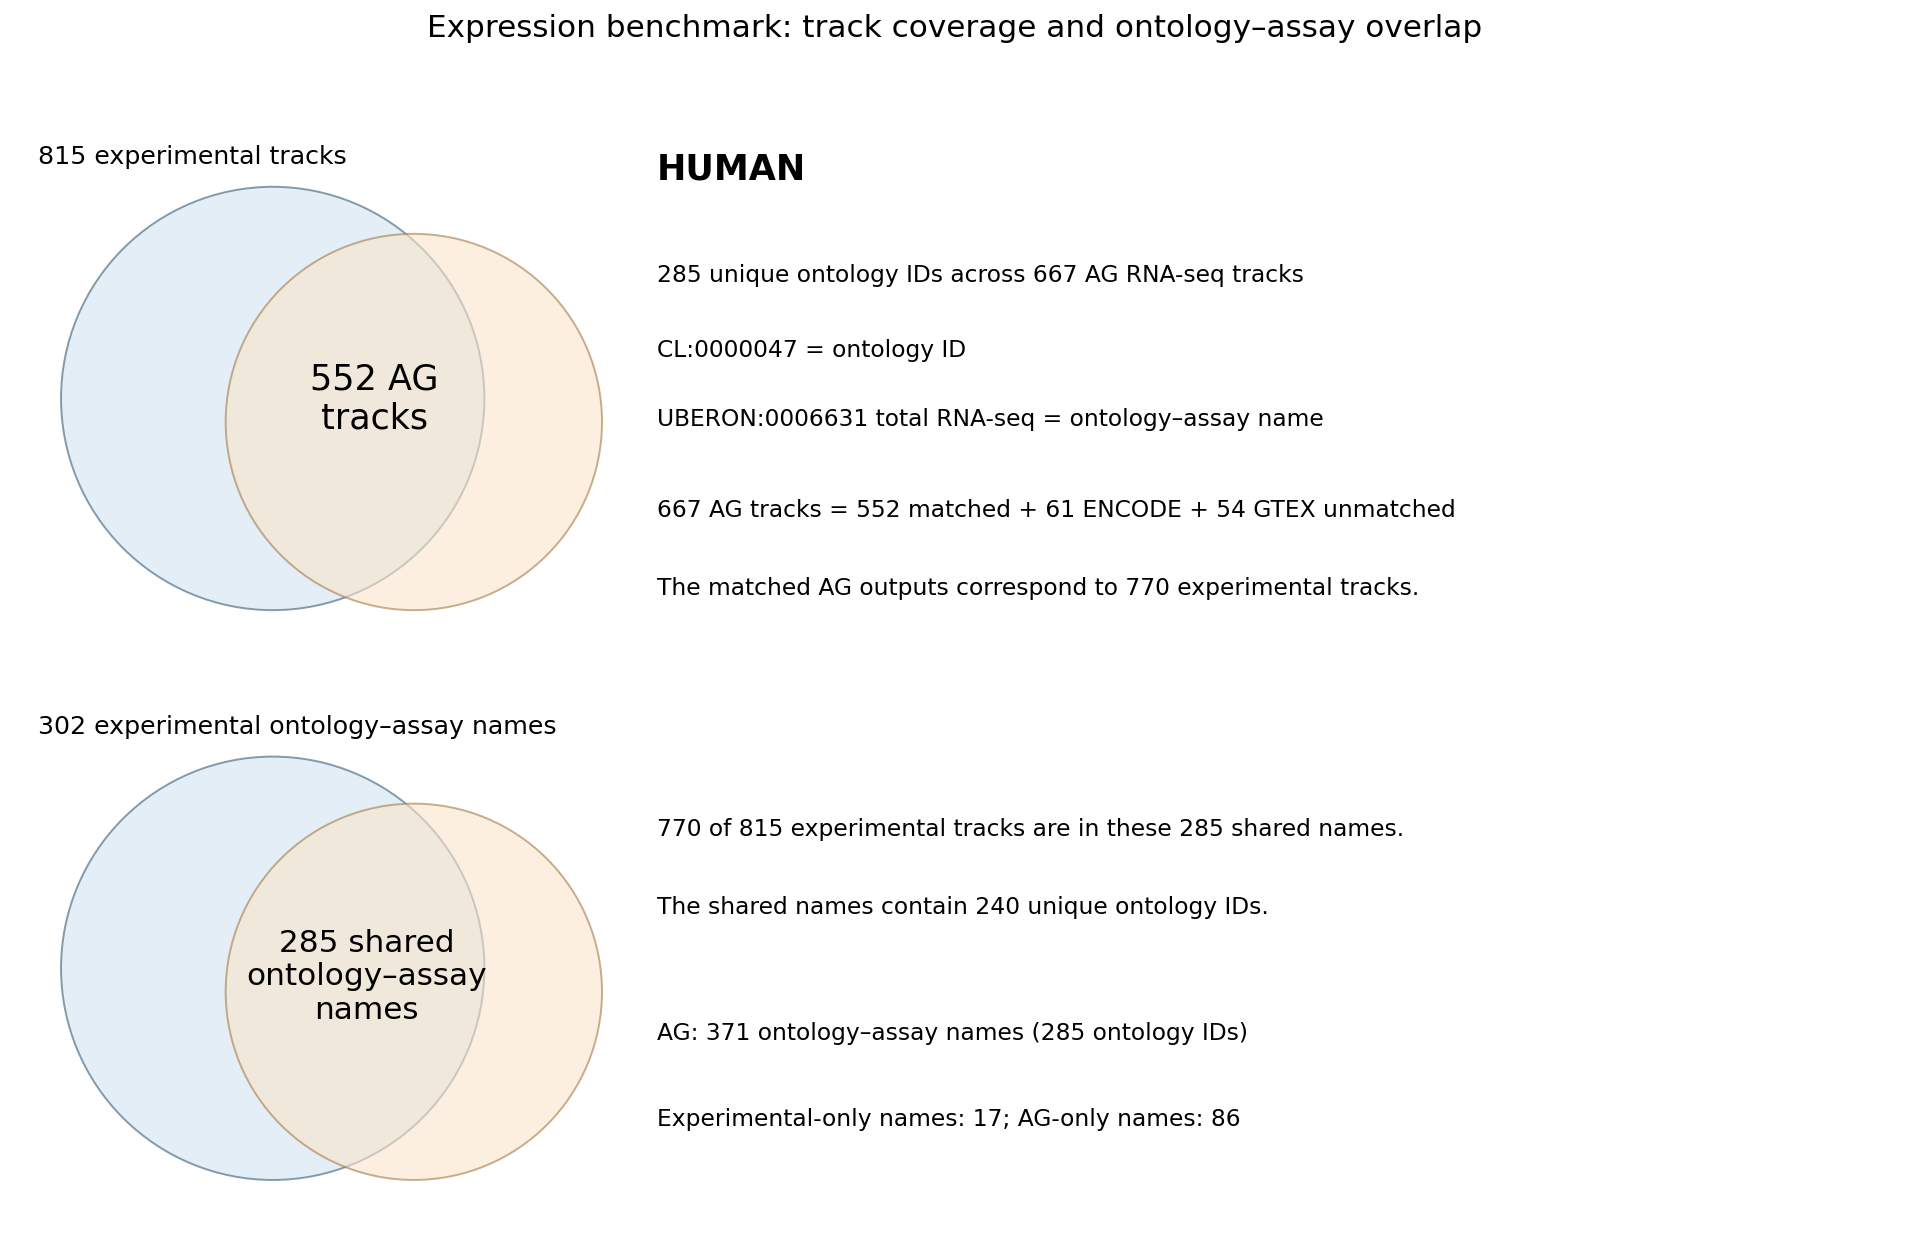

Input: 815 tracks / 302 names
AG: 667 tracks / 371 names / 285 ontology IDs
Matched: 770 input tracks / 552 AG tracks / 285 names / 240 ontology IDs


In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# All counts come from the input, ENCODE resolution and AG metadata above.
input_names = set(resolved.loc[(resolved.ontology_curie != '') & (resolved.assay != ''),
                              'ontology_curie'] + ' ' +
                  resolved.loc[(resolved.ontology_curie != '') & (resolved.assay != ''), 'assay'])
ag_names = set(metadata['name'])
shared_names = set(summary.loc[summary.alphagenome_ontology_assay_supported == 'yes',
                               'alphagenome_ontology_name'])
matched_input = summary[summary.alphagenome_ontology_assay_supported == 'yes']
matched_ag = metadata[metadata['name'].isin(shared_names)]
unmatched_ag = metadata[~metadata['name'].isin(shared_names)]
unmatched_sources = unmatched_ag['data_source'].value_counts()
shared_ontologies = set(matched_input['ontology_curie'])
ag_ontology_count = metadata['ontology_curie'].nunique()

fig, axes = plt.subplots(2, 1, figsize=(14, 9))
for ax in axes:
    ax.set(xlim=(0, 12), ylim=(0, 3.5), aspect='equal')
    ax.axis('off')
    ax.add_patch(Circle((1.65, 1.65), 1.35, facecolor='#d9e8f3', edgecolor='#54738a', alpha=0.7))
    ax.add_patch(Circle((2.55, 1.5), 1.2, facecolor='#fae5cc', edgecolor='#a37b48', alpha=0.6))

ax = axes[0]
ax.text(0.15, 3.15, f'{len(input_table)} experimental tracks', fontsize=13)
ax.text(2.3, 1.65, f'{len(matched_ag)} AG\ntracks', ha='center', va='center', fontsize=18)
ax.text(4.1, 3.05, ORGANISM.upper(), fontsize=18, weight='bold')
ax.text(4.1, 2.4, f'{ag_ontology_count} unique ontology IDs across {len(metadata)} AG RNA-seq tracks', fontsize=12)
ax.text(4.1, 1.92, 'CL:0000047 = ontology ID', fontsize=12)
ax.text(4.1, 1.48, 'UBERON:0006631 total RNA-seq = ontology–assay name', fontsize=12)
source_parts = ' + '.join(f'{int(count)} {source.upper()}' for source, count in unmatched_sources.items())
ax.text(4.1, 0.9, f'{len(metadata)} AG tracks = {len(matched_ag)} matched + {source_parts} unmatched', fontsize=12)
ax.text(4.1, 0.4, f'The matched AG outputs correspond to {len(matched_input)} experimental tracks.', fontsize=12)

ax = axes[1]
ax.text(0.15, 3.15, f'{len(input_names)} experimental ontology–assay names', fontsize=13)
ax.text(2.25, 1.6, f'{len(shared_names)} shared\nontology–assay\nnames', ha='center', va='center', fontsize=16)
ax.text(4.1, 2.5, f'{len(matched_input)} of {len(input_table)} experimental tracks are in these {len(shared_names)} shared names.', fontsize=12)
ax.text(4.1, 2.0, f'The shared names contain {len(shared_ontologies)} unique ontology IDs.', fontsize=12)
ax.text(4.1, 1.2, f'AG: {len(ag_names)} ontology–assay names ({ag_ontology_count} ontology IDs)', fontsize=12)
ax.text(4.1, 0.65, f'Experimental-only names: {len(input_names - ag_names)}; AG-only names: {len(ag_names - input_names)}', fontsize=12)
fig.suptitle('Expression benchmark: track coverage and ontology–assay overlap', fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plot_path = ROOT / 'results' / f'ontology_overlap_{ORGANISM}.png'
plot_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(plot_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Input: {len(input_table)} tracks / {len(input_names)} names')
print(f'AG: {len(metadata)} tracks / {len(ag_names)} names / {ag_ontology_count} ontology IDs')
print(f'Matched: {len(matched_input)} input tracks / {len(matched_ag)} AG tracks / '
      f'{len(shared_names)} names / {len(shared_ontologies)} ontology IDs')


## 5. Record sources and continue

The full human reference input contains 815 sample rows. The earlier analysis
found 770 samples in 285 shared names; these are a comparison point, not a forced
result. Live metadata changes or unresolved requests can change the rebuilt table.
Review the status/error columns before using it.

Continue with `ontology_mapping_explained.ipynb` for group-level counts and plots.
Generate representative/all-sample JSON mappings from the resolved table using
`prepare_expression_mapping.py --ontology-map ... --metadata ...` as in the README.

The command-line equivalent of all the steps above is:

```bash
python benchmarks/expression/scripts/build_alphagenome_ontology_map.py --file-mappings data/file_mappings_borzoi_and_v1_human.csv --organism human
```


In [7]:
assert len(summary) == len(input_rows)
assert summary.id.tolist() == input_table.id.tolist()
print('Verified: one output row per selected input sample, in the same order.')


Verified: one output row per selected input sample, in the same order.
